Naslov + Uvod

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

skladi = pd.read_csv("podatki/skladi.csv")
vep = pd.read_csv("podatki/vep.csv", parse_dates=["datum"])
skladi.head()


,sklad,upravljavec,upravljavec_id,datum,vep,valuta,donos_1d,donos_6m,donos_12m,donos_60m
0,Generali Amerika,Generali Investments,generali_investments,2026-10-16,3.49,EUR,-1.91,12.88,14.58,74.72
1,Generali Bond,Generali Investments,generali_investments,2026-10-16,17.88,EUR,-0.06,-1.84,-2.87,-9.91
2,Generali Corporate Bonds,Generali Investments,generali_investments,2026-10-16,0.99,EUR,0.02,-0.72,-1.48,-0.42
3,Generali Galileo,Generali Investments,generali_investments,2026-10-16,17.06,EUR,-0.47,6.62,11.23,31.81
4,Generali Globalni,Generali Investments,generali_investments,2026-10-16,15.84,EUR,-0.73,9.49,15.49,52.37


In [2]:
vep = vep[vep["datum"] >= "2023-01-01"]


Število skladov: 72


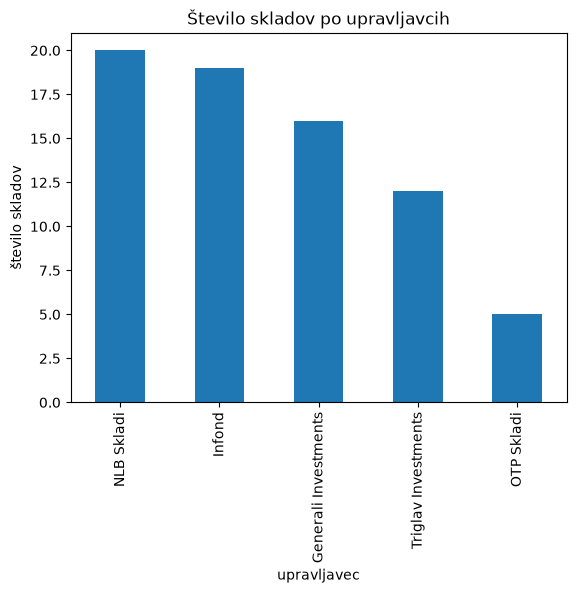

In [3]:
print("Število skladov:", len(skladi))
skladi["upravljavec"].value_counts().plot.bar(
    title="Število skladov po upravljavcih"
)
plt.ylabel("število skladov")
plt.show()


In [4]:
skladi[["donos_6m", "donos_12m", "donos_60m"]].describe().round(2)


,donos_6m,donos_12m,donos_60m
count,72.00,71.00,71.00
mean,6.94,14.14,42.65
std,5.91,11.38,39.71
min,-5.73,-16.13,-28.91
25%,2.34,7.02,17.88
50%,6.88,14.58,36.40
75%,11.11,19.19,60.15
max,23.22,43.02,169.74


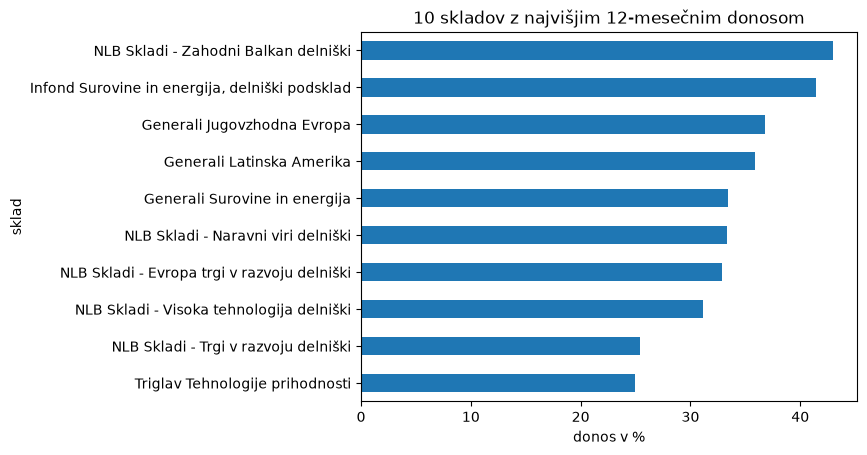

In [5]:
najboljsi = skladi.nlargest(10, "donos_12m").set_index("sklad")
najboljsi["donos_12m"].sort_values().plot.barh(
    title="10 skladov z najvišjim 12-mesečnim donosom"
)
plt.xlabel("donos v %")
plt.show()


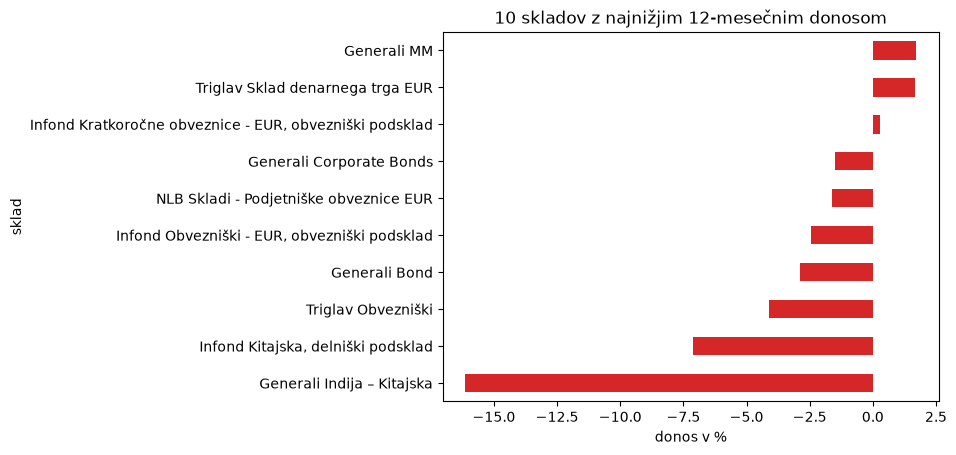

In [6]:
najslabsi = skladi.nsmallest(10, "donos_12m").set_index("sklad")
najslabsi["donos_12m"].sort_values().plot.barh(
    title="10 skladov z najnižjim 12-mesečnim donosom", color="tab:red"
)
plt.xlabel("donos v %")
plt.show()


Negativen 12-mesečni donos ima 7 od 72 skladov (10%).


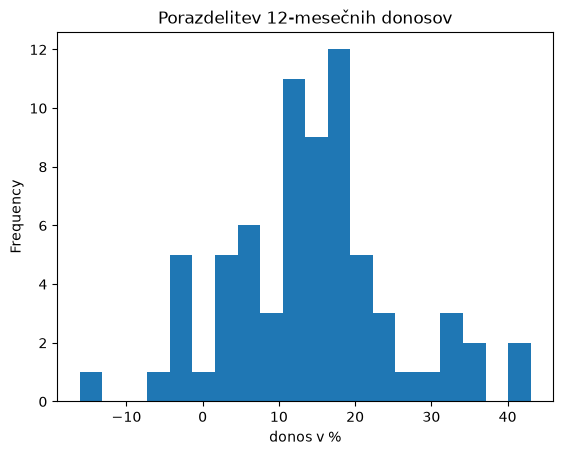

In [7]:
negativni = skladi[skladi["donos_12m"] < 0]
delez = len(negativni) / len(skladi)
print(f"Negativen 12-mesečni donos ima {len(negativni)} "
      f"od {len(skladi)} skladov ({delez:.0%}).")
skladi["donos_12m"].plot.hist(
    bins=20, title="Porazdelitev 12-mesečnih donosov"
)
plt.xlabel("donos v %")
plt.show()


In [8]:
po_upravljavcih = (
    skladi.groupby("upravljavec")[["donos_12m", "donos_60m"]]
    .mean()
    .sort_values("donos_12m")
)
po_upravljavcih.round(2)


,donos_12m,donos_60m
upravljavec,,
Infond,11.53,32.14
Generali Investments,13.48,49.41
Triglav Investments,13.78,38.24
OTP Skladi,15.07,38.66
NLB Skladi,17.08,51.21


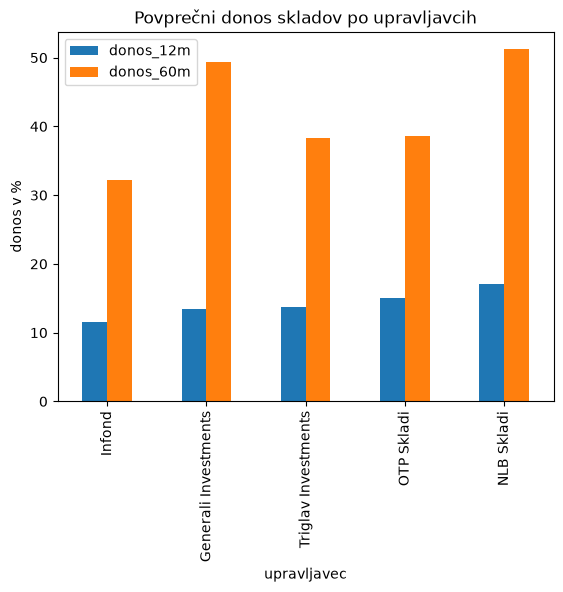

In [9]:
po_upravljavcih.plot.bar(title="Povprečni donos skladov po upravljavcih")
plt.ylabel("donos v %")
plt.show()


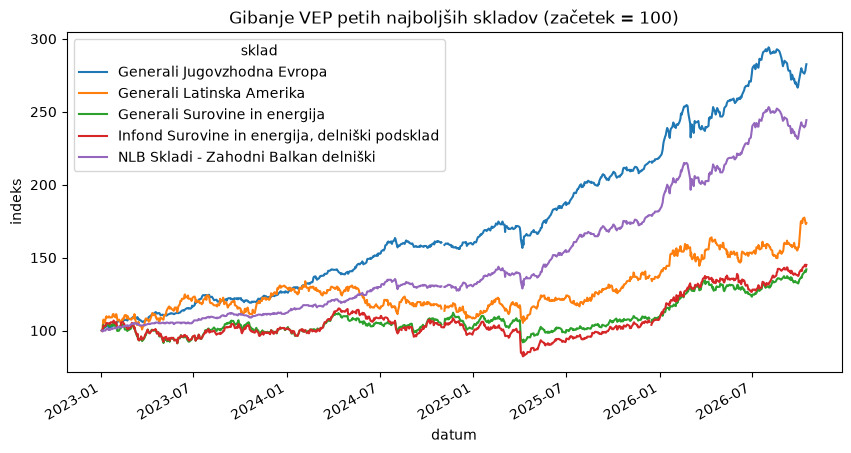

In [10]:
izbrani = najboljsi.index[:5]
tabela = vep[vep["sklad"].isin(izbrani)].pivot(
    index="datum", columns="sklad", values="vep"
)
indeks = tabela / tabela.bfill().iloc[0] * 100
indeks.plot(
    title="Gibanje VEP petih najboljših skladov (začetek = 100)",
    figsize=(10, 5),
)
plt.ylabel("indeks")
plt.show()


In [11]:
vep = vep.sort_values(["sklad", "datum"])
vep["sprememba"] = vep.groupby("sklad")["vep"].pct_change() * 100
nihajnost = vep.groupby("sklad")["sprememba"].std().rename("nihajnost")
nihajnost.sort_values(ascending=False).head(10).round(2)


sklad
Infond Megatrendi, delniški podsklad razvitih trgov    1.73
Infond Kitajska, delniški podsklad                     1.58
NLB Skladi - Visoka tehnologija delniški               1.54
Infond Tehnologija, delniški podsklad                  1.54
Triglav Tehnologije prihodnosti                        1.50
Triglav Okoljska perspektiva                           1.48
Generali Tehnologija                                   1.37
Triglav Trgi v razvoju                                 1.26
Triglav Severna Amerika                                1.21
NLB Skladi - Azija delniški                            1.21
Name: nihajnost, dtype: float64

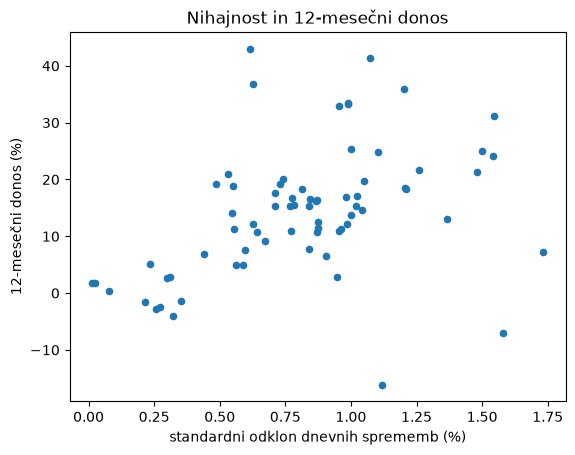

Korelacija: 0.4


In [12]:
skladi = skladi.join(nihajnost, on="sklad")
skladi.plot.scatter(
    x="nihajnost", y="donos_12m", title="Nihajnost in 12-mesečni donos"
)
plt.xlabel("standardni odklon dnevnih sprememb (%)")
plt.ylabel("12-mesečni donos (%)")
plt.show()
korelacija = skladi["nihajnost"].corr(skladi["donos_12m"])
print("Korelacija:", round(korelacija, 2))


Zaključek